1. Разведочный анализ данных

Импорт данных:

данные о семи видах рыб для продажи

Species - видовое название рыбы

Weight  - вес рыбы в граммах

Length1 - длина по вертикали в см.

Length2 - длина по диагонали в см.

Length3 - поперечная длина в см.

Height  - высота в см.

Width   - ширина по диагонали в см.



In [79]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import scipy.stats as stats
import seaborn as sns
import math

In [80]:
fish = pd.read_csv('Fish.csv')
# fish.tail()
fish.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


In [81]:
fish.info()


<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    str    
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 9.6 KB


In [82]:
fish.describe()

,Weight,Length1,Length2,Length3,Height,Width
count,159.000000,159.000000,159.000000,159.000000,159.000000,159.000000
mean,398.326415,26.247170,28.415723,31.227044,8.970994,4.417486
std,357.978317,9.996441,10.716328,11.610246,4.286208,1.685804
min,0.000000,7.500000,8.400000,8.800000,1.728400,1.047600
25%,120.000000,19.050000,21.000000,23.150000,5.944800,3.385650
50%,273.000000,25.200000,27.300000,29.400000,7.786000,4.248500
75%,650.000000,32.700000,35.500000,39.650000,12.365900,5.584500
max,1650.000000,59.000000,63.400000,68.000000,18.957000,8.142000


In [83]:
fish[fish['Weight'] == 0]

,Species,Weight,Length1,Length2,Length3,Height,Width
40,Roach,0.0,19.0,20.5,22.8,6.4752,3.3516


In [84]:
fish[fish['Weight'] > 0].groupby('Species').agg({'Weight': ['mean', 'count']})

Weight      
                 mean count
Species                    
Bream      617.828571    35
Parkki     154.818182    11
Perch      382.239286    56
Pike       718.705882    17
Roach      160.052632    19
Smelt       11.178571    14
Whitefish  531.000000     6

Bream - Лещь

Roach - Плотва

Parkki - Густера

Perch - Окунь

Smelt - Корюшка

Pike - Щука

Whitefish - Сиг

In [85]:
fish.Species = fish['Species'].apply(lambda x: x.replace('Whitefish', 'Сиг'))
fish.Species = fish['Species'].apply(lambda x: x.replace('Pike', 'Щука'))
fish.Species = fish['Species'].apply(lambda x: x.replace('Smelt', 'Корюшка'))
fish.Species = fish['Species'].apply(lambda x: x.replace('Perch', 'Окунь'))
fish.Species = fish['Species'].apply(lambda x: x.replace('Roach', 'Плотва'))
fish.Species = fish['Species'].apply(lambda x: x.replace('Bream', 'Лещь'))
fish.Species = fish['Species'].apply(lambda x: x.replace('Parkki', 'Густера'))
fish

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Лещь,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Лещь,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Лещь,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Лещь,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Лещь,430.0,26.5,29.0,34.0,12.4440,5.1340
...,...,...,...,...,...,...,...
154,Корюшка,12.2,11.5,12.2,13.4,2.0904,1.3936
155,Корюшка,13.4,11.7,12.4,13.5,2.4300,1.2690
156,Корюшка,12.2,12.1,13.0,13.8,2.2770,1.2558
157,Корюшка,19.7,13.2,14.3,15.2,2.8728,2.0672


In [86]:
fish[fish['Weight'] > 0].groupby('Species').agg({'Weight': ['mean', 'count']})

Weight      
               mean count
Species                  
Густера  154.818182    11
Корюшка   11.178571    14
Лещь     617.828571    35
Окунь    382.239286    56
Плотва   160.052632    19
Сиг      531.000000     6
Щука     718.705882    17

In [87]:
fish.at[40, 'Weight'] = fish[(fish.Species == 'Плотва') & (fish.Weight > 0)]['Weight'].mean()
fish.iloc[40]

Species        Плотва
Weight     160.052632
Length1          19.0
Length2          20.5
Length3          22.8
Height         6.4752
Width          3.3516
Name: 40, dtype: object

In [88]:
fish[fish['Weight'] > 0].groupby('Species').agg({'Weight': ['mean', 'count']})

Weight      
               mean count
Species                  
Густера  154.818182    11
Корюшка   11.178571    14
Лещь     617.828571    35
Окунь    382.239286    56
Плотва   160.052632    20
Сиг      531.000000     6
Щука     718.705882    17

1.2. Гистограммы и описательные статистики

<Axes: >

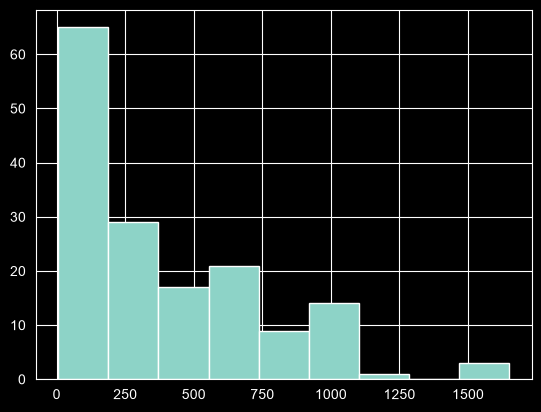

In [89]:
fish.Weight.hist(bins='sturges')

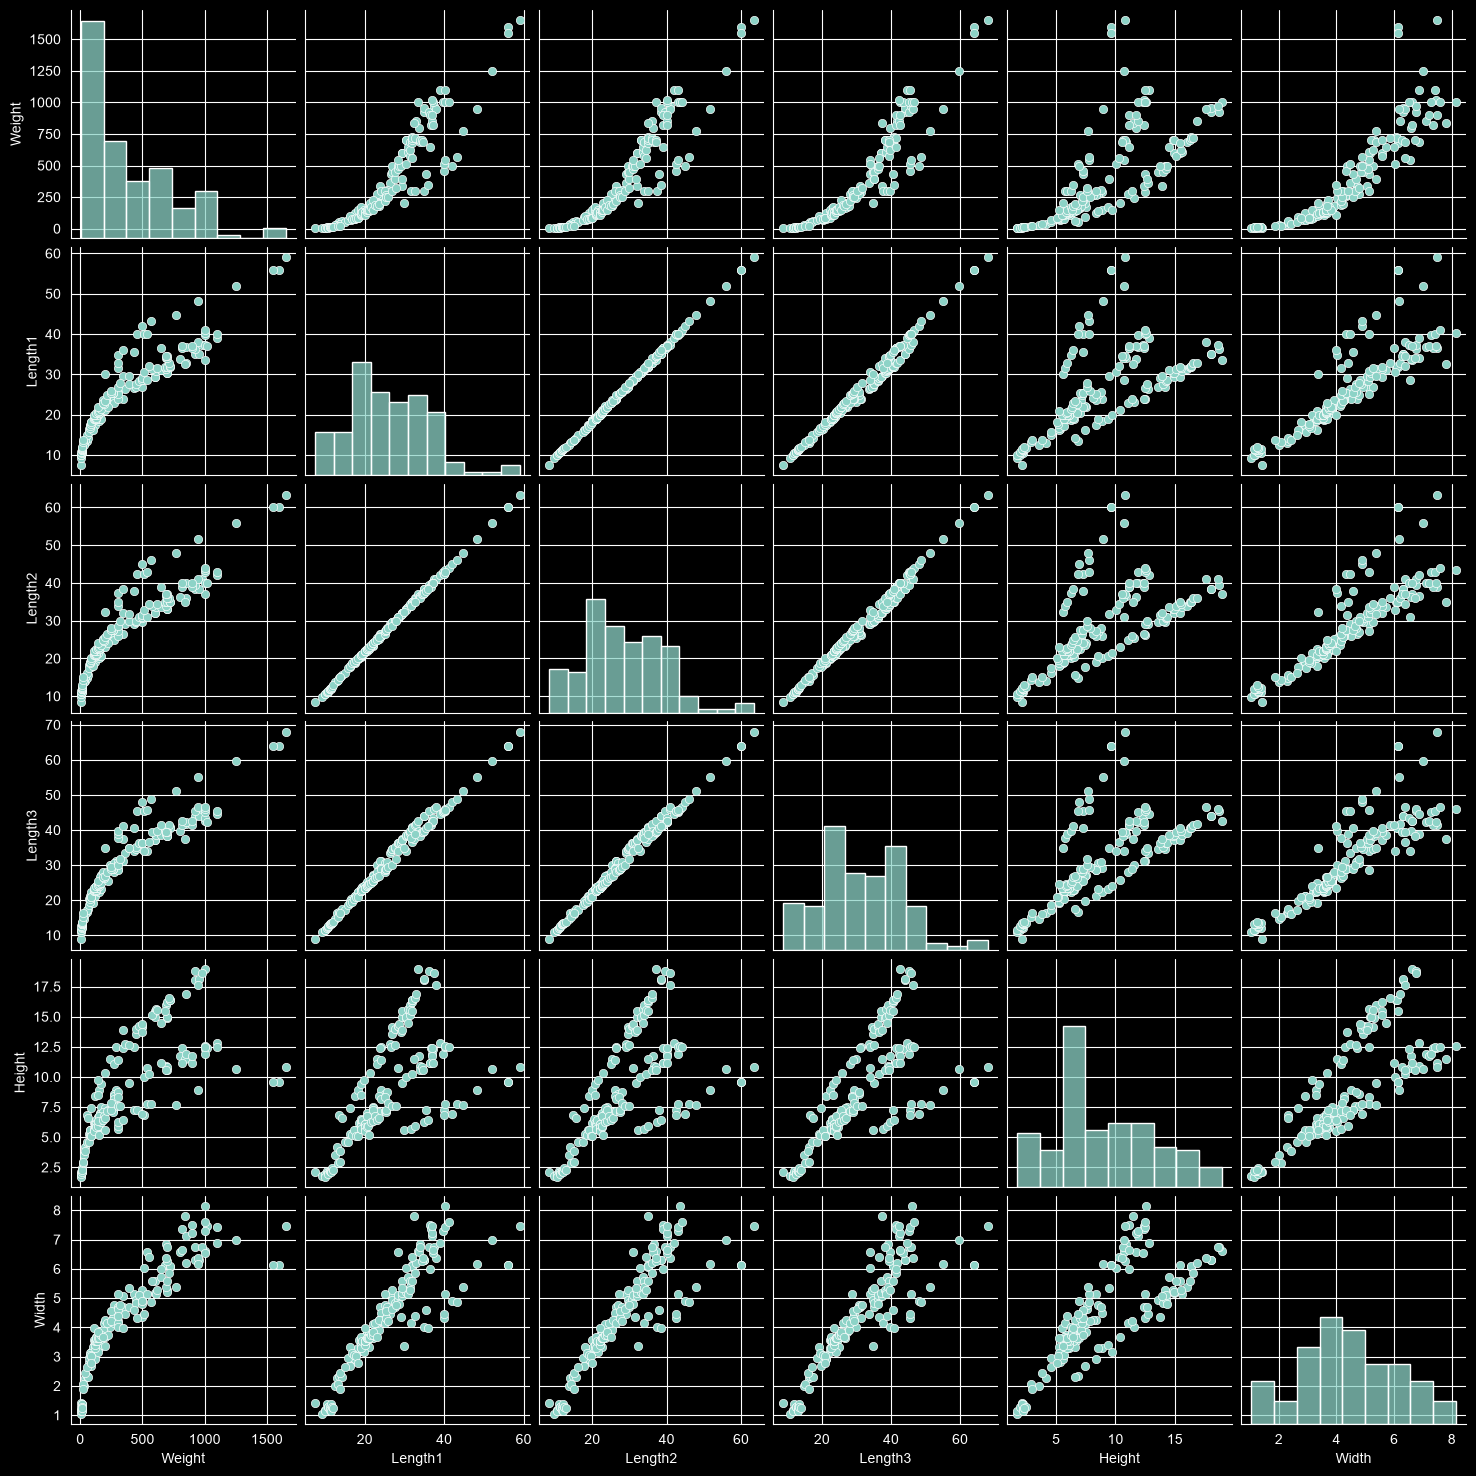

In [90]:
col = ['Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']
sns.pairplot(fish.loc[:, col])

1.3. Проверка нормальности по критерию Шапиро - Уилка

свыше 5000 наблюдений используем д'Агостино - Пирсона


In [91]:
stats.shapiro(fish.Weight)

ShapiroResult(statistic=np.float64(0.8824602990212519), pvalue=np.float64(6.736359963194659e-10))

In [92]:
Norm = pd.DataFrame(columns=['p-value', 'Norm'], index=col)
for c in col:
    Norm.at[c, 'p-value'] = stats.shapiro(fish[c])[1]
    if stats.shapiro(fish[c])[1] > .05:
        Norm.at[c, 'Norm'] = 'Normal'
    else:
        Norm.at[c, 'Norm'] = 'Unknown'
Norm

,p-value,Norm
Weight,0.0,Unknown
Length1,0.001771,Unknown
Length2,0.003052,Unknown
Length3,0.002963,Unknown
Height,0.000185,Unknown
Width,0.015363,Unknown


1.4. анализ влияния категориальных признаков. Критерии сравнения групп

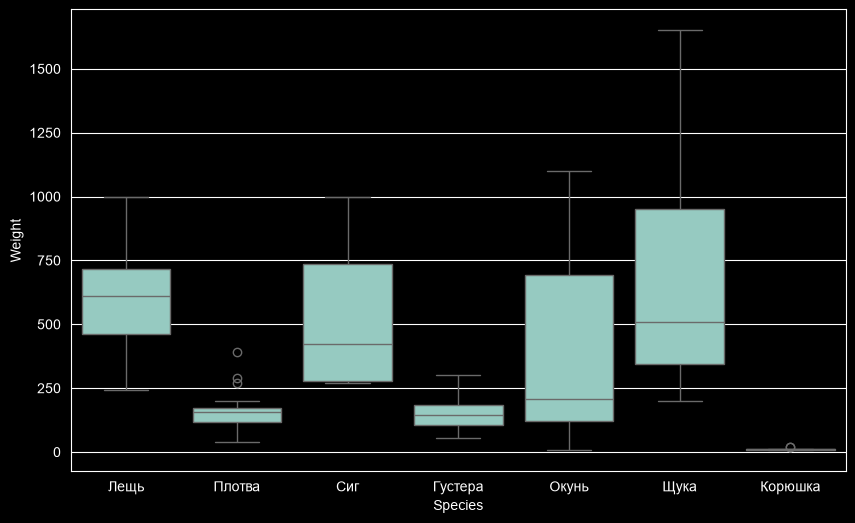

In [93]:
f, ax = plt.subplots(figsize=(10, 6))
fig = sns.boxplot(x='Species', y='Weight', data=fish)

In [94]:
fish.groupby('Species')[['Weight']].median()


,Weight
Species,
Густера,145.00
Корюшка,9.85
Лещь,610.00
Окунь,207.50
Плотва,155.00
Сиг,423.00
Щука,510.00


Критерий Краскала-Уоллиса

это непараметрический критерий, используетс я для сравнения трех или более независимых выборок

Гипоза H0: медианные знаения выборок не имеют статистически значимых отличий. Уровень значимости 0.05



In [95]:
fish1 = np.array(fish[fish.Species == 'Лещь']['Weight'])
fish2 = np.array(fish[fish.Species == 'Густера']['Weight'])
fish3 = np.array(fish[fish.Species == 'Плотва']['Weight'])
fish4 = np.array(fish[fish.Species == 'Щука']['Weight'])
fish5 = np.array(fish[fish.Species == 'Окунь']['Weight'])
fish6 = np.array(fish[fish.Species == 'Корюшка']['Weight'])
fish7 = np.array(fish[fish.Species == 'Сиг']['Weight'])
stats.mstats.kruskalwallis(fish1, fish2, fish3, fish4, fish5, fish6, fish7)



KruskalResult(statistic=np.float64(79.97626227572155), pvalue=np.float64(3.613432706212754e-15))

In [96]:
# stats.mstats.kruskalwallis(fish2, fish3)

1.5. Анализ влияния количественных признаков

In [97]:
fish[col].corr()


,Weight,Length1,Length2,Length3,Height,Width
Weight,1.000000,0.915971,0.918846,0.923319,0.724526,0.886955
Length1,0.915971,1.000000,0.999517,0.992031,0.625378,0.867050
Length2,0.918846,0.999517,1.000000,0.994103,0.640441,0.873547
Length3,0.923319,0.992031,0.994103,1.000000,0.703409,0.878520
Height,0.724526,0.625378,0.640441,0.703409,1.000000,0.792881
Width,0.886955,0.867050,0.873547,0.878520,0.792881,1.000000


<Axes: >

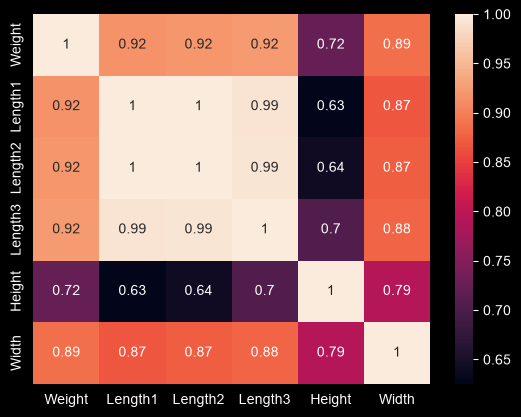

In [98]:
sns.heatmap(fish[col].corr(), annot=True)

2. Построение нелинейной регрессии

2.1. Оценка параметров модели.

In [99]:
fish.info()

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    str    
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 10.4 KB


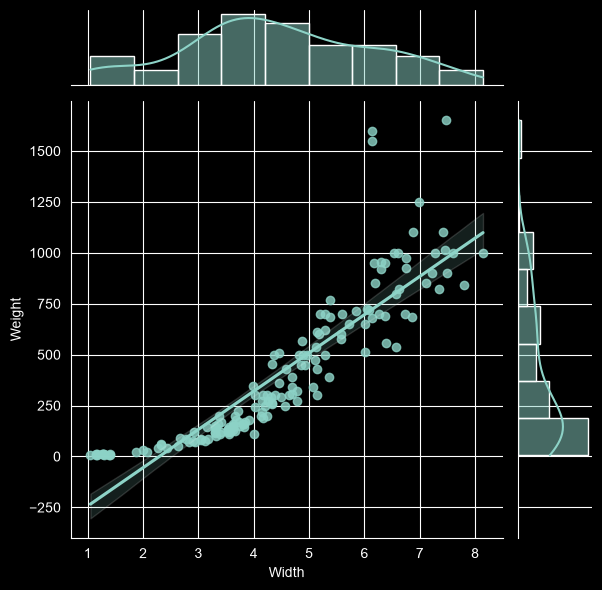

In [100]:
sns.jointplot(x='Width', y='Weight', data=fish, kind='reg')

In [101]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

Bream - Лещь

Roach - Плотва

Parkki - Густера

Perch - Окунь

Smelt - Корюшка

Pike - Щука

Whitefish - Сиг


In [102]:
results1 = smf.ols('Weight ~ Width', data=fish[fish.Species == 'Окунь']).fit()
results1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Weight   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.928
Method:                 Least Squares   F-statistic:                     708.6
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           1.01e-32
Time:                        15:45:58   Log-Likelihood:                -332.48
No. Observations:                  56   AIC:                             669.0
Df Residuals:                      54   BIC:                             673.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   -513.8451     35.901    -14.313      0.000    -585.822    -441.869
Width        188.8194      7.093     26.619      0.000     174.598     203.041
==============================================================================
Omnibus:                       18.352   Durbin-Watson:                   0.680
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               24.007
Skew:                           1.240   Prob(JB):                     6.12e-06
Kurtosis:                       5.034   Cond. No.                         15.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [103]:
fish['Width1'] = np.log(fish['Width'])
fish['Weight1'] = np.log(fish['Weight'])

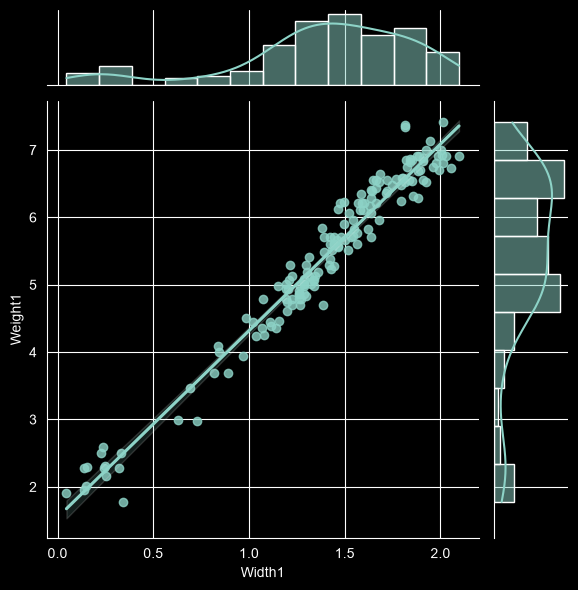

In [104]:
sns.jointplot(x='Width1', y='Weight1', data=fish, kind='reg')


In [105]:
results2 = smf.ols('Weight1 ~ Width1', data=fish).fit()
results2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                Weight1   R-squared:                       0.960
Model:                            OLS   Adj. R-squared:                  0.960
Method:                 Least Squares   F-statistic:                     3792.
Date:                Sat, 03 Oct 2026   Prob (F-statistic):          7.34e-112
Time:                        15:45:59   Log-Likelihood:                -13.136
No. Observations:                 159   AIC:                             30.27
Df Residuals:                     157   BIC:                             36.41
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.5458      0.066     23.374      0.000       1.415       1.676
Width1         2.7715      0.045     61.579      0.000       2.683       2.860
==============================================================================
Omnibus:                        1.429   Durbin-Watson:                   0.868
Prob(Omnibus):                  0.490   Jarque-Bera (JB):                1.051
Skew:                           0.172   Prob(JB):                        0.591
Kurtosis:                       3.200   Cond. No.                         6.63
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [106]:
results3 = smf.ols('Weight1 ~ Width1 + Species', data=fish).fit()
results3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                Weight1   R-squared:                       0.984
Model:                            OLS   Adj. R-squared:                  0.983
Method:                 Least Squares   F-statistic:                     1302.
Date:                Sat, 03 Oct 2026   Prob (F-statistic):          1.62e-131
Time:                        15:45:59   Log-Likelihood:                 57.729
No. Observations:                 159   AIC:                            -99.46
Df Residuals:                     151   BIC:                            -74.91
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              1.8039      0.078     22.982      0.000       1.649       1.959
Species[T.Корюшка]    -0.1876      0.083     -2.269      0.025      -0.351      -0.024
Species[T.Лещь]        0.0131      0.066      0.200      0.842      -0.116       0.143
Species[T.Окунь]      -0.3607      0.059     -6.066      0.000      -0.478      -0.243
Species[T.Плотва]     -0.3076      0.065     -4.721      0.000      -0.436      -0.179
Species[T.Сиг]        -0.2092      0.092     -2.281      0.024      -0.390      -0.028
Species[T.Щука]        0.2307      0.071      3.262      0.001       0.091       0.370
Width1                 2.7029      0.051     52.971      0.000       2.602       2.804
==============================================================================
Omnibus:                       11.682   Durbin-Watson:                   1.863
Prob(Omnibus):                  0.003   Jarque-Bera (JB):               22.558
Skew:                          -0.289   Prob(JB):                     1.26e-05
Kurtosis:                       4.752   Cond. No.                         19.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Мультиколлинеарность внутри признака Species


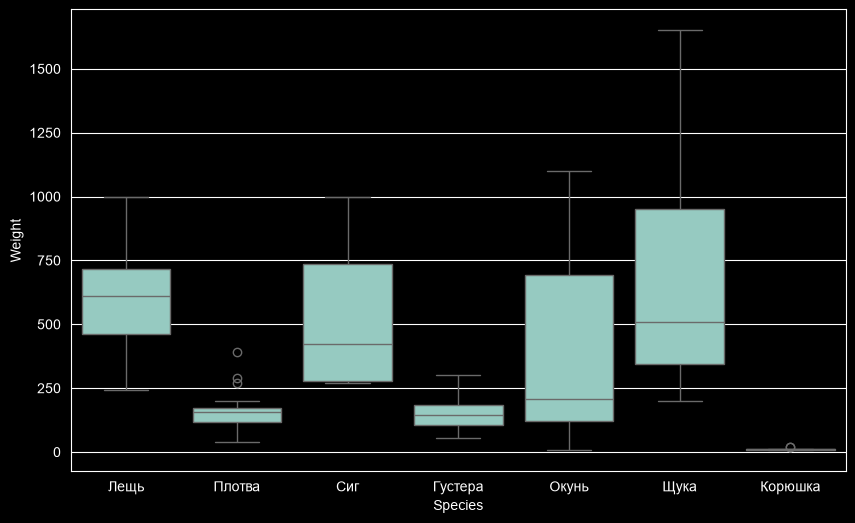

In [107]:
f, ax = plt.subplots(figsize=(10, 6))
fig = sns.boxplot(x='Species', y='Weight', data=fish)

In [108]:
fish1 = fish[fish.Species == 'Плотва']['Weight']
fish2 = fish[fish.Species == 'Густера']['Weight']
scipy.stats.mannwhitneyu(fish1, fish2)

MannwhitneyuResult(statistic=np.float64(114.0), pvalue=np.float64(0.8850008201769074))

In [109]:
fish.loc[fish.Species.str.contains('Плотва|Густера'), 'Species'] = 'Плотва_Густера'


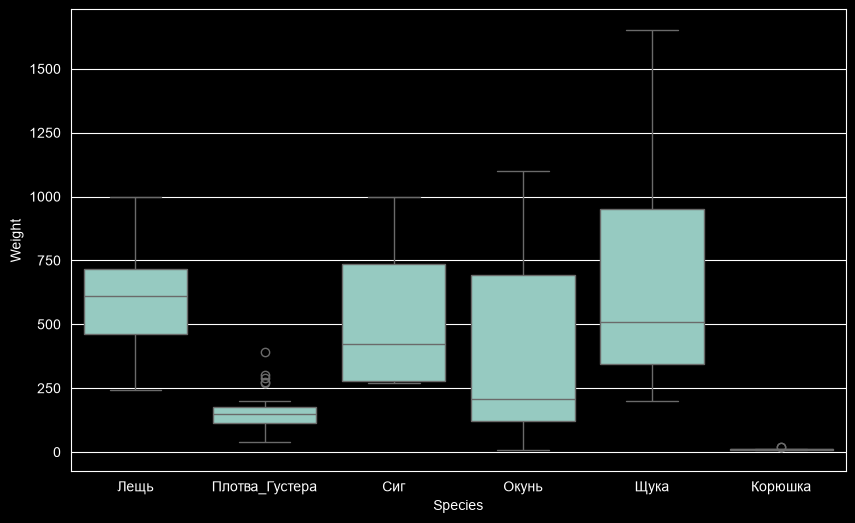

In [110]:
f, ax = plt.subplots(figsize=(10, 6))
fig = sns.boxplot(x='Species', y='Weight', data=fish)

In [111]:
results4 = smf.ols('Weight1 ~ Width1 + Species', data=fish).fit()
results4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                Weight1   R-squared:                       0.981
Model:                            OLS   Adj. R-squared:                  0.981
Method:                 Least Squares   F-statistic:                     1329.
Date:                Sat, 03 Oct 2026   Prob (F-statistic):          1.38e-128
Time:                        15:45:59   Log-Likelihood:                 46.784
No. Observations:                 159   AIC:                            -79.57
Df Residuals:                     152   BIC:                            -58.08
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
=============================================================================================
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept                     1.6230      0.051     31.524      0.000       1.521       1.725
Species[T.Лещь]               0.2350      0.096      2.447      0.016       0.045       0.425
Species[T.Окунь]             -0.1436      0.086     -1.676      0.096      -0.313       0.026
Species[T.Плотва_Густера]     0.0125      0.079      0.158      0.874      -0.143       0.168
Species[T.Сиг]                0.0126      0.118      0.107      0.915      -0.220       0.245
Species[T.Щука]               0.4506      0.098      4.595      0.000       0.257       0.644
Width1                        2.6786      0.054     49.417      0.000       2.571       2.786
==============================================================================
Omnibus:                        5.913   Durbin-Watson:                   1.661
Prob(Omnibus):                  0.052   Jarque-Bera (JB):                6.895
Skew:                          -0.257   Prob(JB):                       0.0318
Kurtosis:                       3.881   Cond. No.                         25.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

2.2.Проверка качества модели


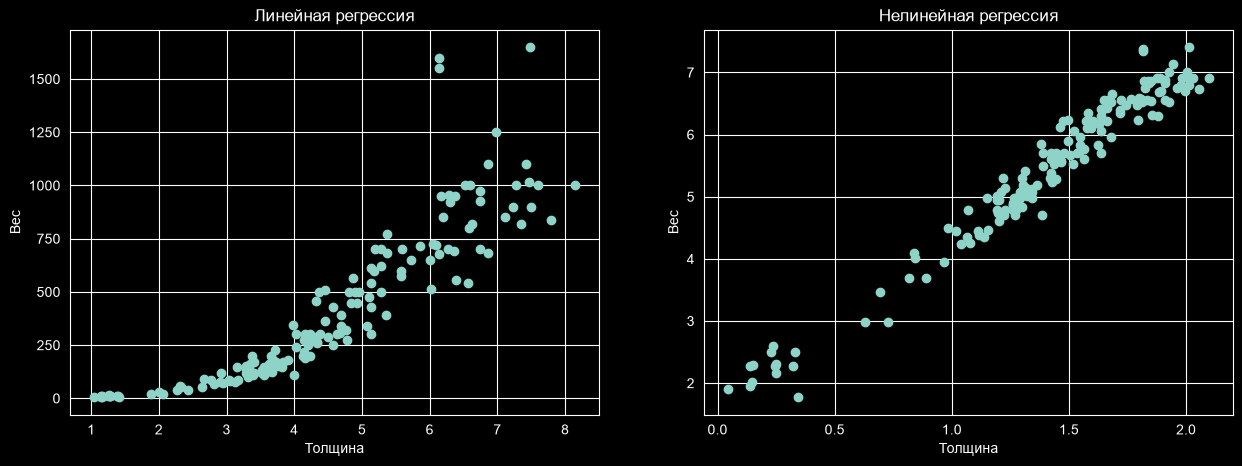

In [112]:
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
ax1.scatter(x=fish['Width'], y=fish['Weight'])
ax1.set_title('Линейная регрессия')
ax1.set_xlabel('Толщина')
ax1.set_ylabel('Вес')

ax2.scatter(x=fish['Width1'], y=fish['Weight1'])
ax2.set_title('Нелинейная регрессия')
ax2.set_xlabel('Толщина')
ax2.set_ylabel('Вес')
plt.show()

In [113]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score

In [114]:
fish = pd.concat([fish, pd.get_dummies(fish.Species, prefix_sep='', dtype='int')], axis=1)
fish

,Species,Weight,Length1,Length2,Length3,Height,Width,Width1,Weight1,Корюшка,Лещь,Окунь,Плотва_Густера,Сиг,Щука
0,Лещь,242.0,23.2,25.4,30.0,11.5200,4.0200,1.391282,5.488938,0,1,0,0,0,0
1,Лещь,290.0,24.0,26.3,31.2,12.4800,4.3056,1.459917,5.669881,0,1,0,0,0,0
2,Лещь,340.0,23.9,26.5,31.1,12.3778,4.6961,1.546732,5.828946,0,1,0,0,0,0
3,Лещь,363.0,26.3,29.0,33.5,12.7300,4.4555,1.494139,5.894403,0,1,0,0,0,0
4,Лещь,430.0,26.5,29.0,34.0,12.4440,5.1340,1.635885,6.063785,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
154,Корюшка,12.2,11.5,12.2,13.4,2.0904,1.3936,0.331890,2.501436,1,0,0,0,0,0
155,Корюшка,13.4,11.7,12.4,13.5,2.4300,1.2690,0.238229,2.595255,1,0,0,0,0,0
156,Корюшка,12.2,12.1,13.0,13.8,2.2770,1.2558,0.227773,2.501436,1,0,0,0,0,0
157,Корюшка,19.7,13.2,14.3,15.2,2.8728,2.0672,0.726195,2.980619,1,0,0,0,0,0


2.2.1 Линейная регрессия

In [115]:
Y1 = fish.Weight
X1 = fish[['Width', 'Плотва_Густера', 'Окунь', 'Щука', 'Корюшка', 'Сиг']]
X1_train, X1_test, Y1_train, Y1_test = train_test_split(X1, Y1, test_size=0.2, random_state=0)


In [116]:
print('Number of data: ', fish.shape[0])
print('Number of train_data: ', X1_train.shape[0])
print('Number of test_data: ', X1_test.shape[0])


Number of data:  159
Number of train_data:  127
Number of test_data:  32


In [117]:
import sklearn.linear_model as lm

LR = lm.LinearRegression()

In [118]:
model1 = LR.fit(X1_train, Y1_train)
model1.intercept_, model1.coef_

(np.float64(-469.36145642099905),
 array([ 200.60611059,  -84.65324944,  -93.71122775,  115.16399977,
         212.43876488, -194.51500372]))

In [119]:
Y1_train_predict = model1.predict(X1_train)
Y1_test_predict = model1.predict(X1_test)

In [120]:
QualityMetrics = ['R2 train', 'R2 test', 'MSE train', 'MSE test']
Models = pd.DataFrame(index=QualityMetrics)
Models.at[QualityMetrics, 'LinearRegressor'] = [r2_score(Y1_train, Y1_train_predict),
                                                r2_score(Y1_test, Y1_test_predict),
                                                mean_squared_error(Y1_train, Y1_train_predict),
                                                mean_squared_error(Y1_test, Y1_test_predict)]
Models

,LinearRegressor
R2 train,0.891951
R2 test,0.812440
MSE train,11859.509579
MSE test,34962.362484


2.2.2 Нелинейная регрессия (линеаризация)

In [121]:
Y2 = fish.Weight1
X2 = fish[['Width1', 'Плотва_Густера', 'Окунь', 'Щука', 'Корюшка', 'Сиг']]
X2_train, X2_test, Y2_train, Y2_test = train_test_split(X2, Y2, test_size=0.2, random_state=0)

In [122]:
model1 = LR.fit(X2_train, Y2_train)
Y2_train_predict = model1.predict(X2_train)
Y2_test_predict = model1.predict(X2_test)


In [123]:
QualityMetrics = ['R2 train', 'R2 test', 'MSE train', 'MSE test']
# Models = pd.DataFrame(index=QualityMetrics)
Models.at[QualityMetrics, 'NonLinearRegressor'] = [r2_score(Y2_train, Y2_train_predict),
                                                   r2_score(Y2_test, Y2_test_predict),
                                                   mean_squared_error(np.exp(Y2_train), np.exp(Y2_train_predict)),
                                                   mean_squared_error(np.exp(Y2_test), np.exp(Y2_test_predict))]
Models

,LinearRegressor,NonLinearRegressor
R2 train,0.891951,0.981952
R2 test,0.812440,0.973504
MSE train,11859.509579,7320.514011
MSE test,34962.362484,17873.414581


2.3. Прогноз

2.3.1. Линейная регрессия

In [124]:
model1 = LR.fit(X1_train, Y1_train)

list(zip(X1_train.columns, model1.coef_))

[('Width', np.float64(200.60611059343285)),
 ('Плотва_Густера', np.float64(-84.65324943934654)),
 ('Окунь', np.float64(-93.7112277468012)),
 ('Щука', np.float64(115.16399977095455)),
 ('Корюшка', np.float64(212.43876487810456)),
 ('Сиг', np.float64(-194.5150037206632))]

In [143]:
x_new_fish = [[3.3, 1, 0, 0, 0, 0]]  # Плотва
y_new_fish = model1.predict(x_new_fish)
Models.at['Forecast', 'LinearRegressor'] = y_new_fish.round(2)[0]
print('Прогноз веса рыбы: ', y_new_fish.round(2)[0])

C:\Users\aligo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


ValueError: X has 6 features, but LinearRegression is expecting 9 features as input.

2.3.2. Нелинейная регрессия (линеаризация)

In [126]:
model2 = LR.fit(X2_train, Y2_train)
model2.intercept_, model2.coef_

(np.float64(1.8030043739410848),
 array([ 2.71520305, -0.22474234, -0.36591625,  0.17950001, -0.17353105,
        -0.340659  ]))

In [127]:
list(zip(X2_train.columns, model2.coef_))

[('Width1', np.float64(2.7152030514679657)),
 ('Плотва_Густера', np.float64(-0.22474234308425306)),
 ('Окунь', np.float64(-0.3659162471809789)),
 ('Щука', np.float64(0.17950001411913288)),
 ('Корюшка', np.float64(-0.1735310542907953)),
 ('Сиг', np.float64(-0.34065899755502804))]

In [128]:
x_new_fish = [[np.log(3.3),1,0,0,0,0]]
y_new_fish = model2.predict(x_new_fish)
y_new_fish = math.exp(y_new_fish[0])

Models.at['Forecast', 'NonLinearRegressor'] = round(y_new_fish,2)
print('Прогноз веса рыбы: ', round(y_new_fish,2))

Прогноз веса рыбы:  123.97


C:\Users\aligo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


3.Полиномиальная модель регрессии


3.1 Оценка параметров модели

In [129]:
from sklearn.preprocessing import PolynomialFeatures

In [130]:
Y3 = fish['Weight']
X3 = fish[['Width', 'Плотва_Густера', 'Окунь', 'Щука', 'Корюшка', 'Сиг']]
X3_train, X3_test, Y3_train, Y3_test = train_test_split(X3, Y3, test_size=0.2, random_state=0)

In [131]:
poly_reg = PolynomialFeatures(degree=3)
X_poly_train = poly_reg.fit_transform(np.array(X3_train['Width']).reshape(-1,1))
X_poly_train

array([[  1.        ,   6.144     ,  37.748736  , 231.92823398],
       [  1.        ,   4.3844    ,  19.22296336,  84.28116056],
       [  1.        ,   5.2854    ,  27.93545316, 147.65004413],
       [  1.        ,   3.723     ,  13.860729  ,  51.60349407],
       [  1.        ,   4.6354    ,  21.48693316,  99.60052997],
       [  1.        ,   5.2801    ,  27.87945601, 147.20631568],
       [  1.        ,   6.7408    ,  45.43838464, 306.29106318],
       [  1.        ,   3.525     ,  12.425625  ,  43.80032813],
       [  1.        ,   6.018     ,  36.216324  , 217.94983783],
       [  1.        ,   2.432     ,   5.914624  ,  14.38436557],
       [  1.        ,   3.825     ,  14.630625  ,  55.96214063],
       [  1.        ,   5.8515    ,  34.24005225, 200.35566574],
       [  1.        ,   2.0672    ,   4.27331584,   8.8337985 ],
       [  1.        ,   4.239     ,  17.969121  ,  76.17110392],
       [  1.        ,   3.906     ,  15.256836  ,  59.59320142],
       [  1.        ,   4

In [132]:
X3_train = pd.concat([pd.DataFrame(X_poly_train, index=X3_train.index, columns=['x0','x1','x2','x3']), X3_train[['Плотва_Густера', 'Окунь', 'Щука', 'Корюшка', 'Сиг']]], axis=1)
model3 = LR.fit(X3_train, Y3_train)
model3.intercept_, model3.coef_

(np.float64(528.4900780718821),
 array([   0.        , -371.34228825,  101.03542365,   -5.4684049 ,
         -91.98623866, -128.6730006 ,  121.18293591, -194.52591294,
        -193.16706553]))

In [133]:
X_poly_test = poly_reg.fit_transform(np.array(X3_test['Width']).reshape(-1,1))
X3_test = pd.concat([pd.DataFrame(X_poly_test, index=X3_test.index, columns=['x0','x1','x2','x3']), X3_test[['Плотва_Густера', 'Окунь', 'Щука', 'Корюшка', 'Сиг']]], axis=1)
X3_test

,x0,x1,x2,x3,Плотва_Густера,Окунь,Щука,Корюшка,Сиг
7,1.0,4.6900,21.996100,103.161709,0,0,0,0,0
40,1.0,3.3516,11.233223,37.649269,1,0,0,0,0
95,1.0,3.7250,13.875625,51.686703,0,1,0,0,0
45,1.0,3.8203,14.594692,55.756102,1,0,0,0,0
110,1.0,6.3875,40.800156,260.610998,0,1,0,0,0
120,1.0,7.2250,52.200625,377.149516,0,1,0,0,0
59,1.0,6.5736,43.212217,284.059829,0,0,0,0,1
131,1.0,4.0198,16.158792,64.955112,0,0,1,0,0
33,1.0,6.7473,45.526057,307.177966,0,0,0,0,0
83,1.0,3.3075,10.939556,36.182582,0,1,0,0,0


3.2. Проверка качества модели

In [134]:
Y3_train_predict = model3.predict(X3_train)
Y3_test_predict = model3.predict(X3_test)
# QualityMetrics = ['R2 train', 'R2 test', 'MSE train', 'MSE test']
# Models = pd.DataFrame(index=QualityMetrics)
Models.at[QualityMetrics, 'Polinomial Model'] = [r2_score(Y3_train, Y3_train_predict),
                                                r2_score(Y3_test, Y3_test_predict),
                                                mean_squared_error(Y3_train, Y3_train_predict),
                                                mean_squared_error(Y3_test, Y3_test_predict)]
Models

,LinearRegressor,NonLinearRegressor,Polinomial Model
R2 train,0.891951,0.981952,0.921328
R2 test,0.812440,0.973504,0.852853
MSE train,11859.509579,7320.514011,8635.126976
MSE test,34962.362484,17873.414581,27429.146680
Forecast,107.990000,123.970000,NaN


3.3. Прогноз веса рыбы

In [135]:
x_new_fish = [[1,3.3, 3.3**2, 3.3**3,1,0,0,0,0]]
y_new_fish = model3.predict(x_new_fish)
Models.at['Forecast', 'Polinomial Model'] = y_new_fish.round(2)[0]
print('Прогноз веса рыбы: ', y_new_fish.round(2)[0])

Прогноз веса рыбы:  114.83


C:\Users\aligo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


4. Дерево решений

4.1. Оценка параметров модели

In [136]:
from sklearn import tree
from sklearn.tree import DecisionTreeRegressor

In [137]:
Y4 = fish['Weight']
X4 = fish[['Width', 'Плотва_Густера', 'Окунь', 'Щука', 'Корюшка', 'Сиг']]
X4_train, X4_test, Y4_train, Y4_test = train_test_split(X4, Y4, test_size=0.2, random_state=0)

In [138]:
dtr = DecisionTreeRegressor(max_depth=4, min_samples_split=3)
model4 = dtr.fit(X4_train, Y4_train)

4.2 Проверка качества модели

In [139]:
Y4_train_predict = model4.predict(X4_train)
Y4_test_predict = model4.predict(X4_test)

In [140]:
Models.at[QualityMetrics, 'Decision Tree'] = [r2_score(Y4_train, Y4_train_predict),
                                                r2_score(Y4_test, Y4_test_predict),
                                                mean_squared_error(Y4_train, Y4_train_predict),
                                                mean_squared_error(Y4_test, Y4_test_predict)]
Models

,LinearRegressor,NonLinearRegressor,Polinomial Model,Decision Tree
R2 train,0.891951,0.981952,0.921328,0.954061
R2 test,0.812440,0.973504,0.852853,0.879016
MSE train,11859.509579,7320.514011,8635.126976,5042.323066
MSE test,34962.362484,17873.414581,27429.146680,22552.147076
Forecast,107.990000,123.970000,114.830000,NaN


4.3. Прогноз

In [141]:
x_new_fish = [[3.3,1,0,0,0,0]]
y_new_fish = model4.predict(x_new_fish)
Models.at['Forecast', 'Decision Tree'] = y_new_fish.round(2)[0]
print('Прогноз веса рыбы: ', y_new_fish.round(2)[0])

C:\Users\aligo\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


Прогноз веса рыбы:  118.57


In [142]:
Models

,LinearRegressor,NonLinearRegressor,Polinomial Model,Decision Tree
R2 train,0.891951,0.981952,0.921328,0.954061
R2 test,0.812440,0.973504,0.852853,0.879016
MSE train,11859.509579,7320.514011,8635.126976,5042.323066
MSE test,34962.362484,17873.414581,27429.146680,22552.147076
Forecast,107.990000,123.970000,114.830000,118.570000


4.4. Визуализация

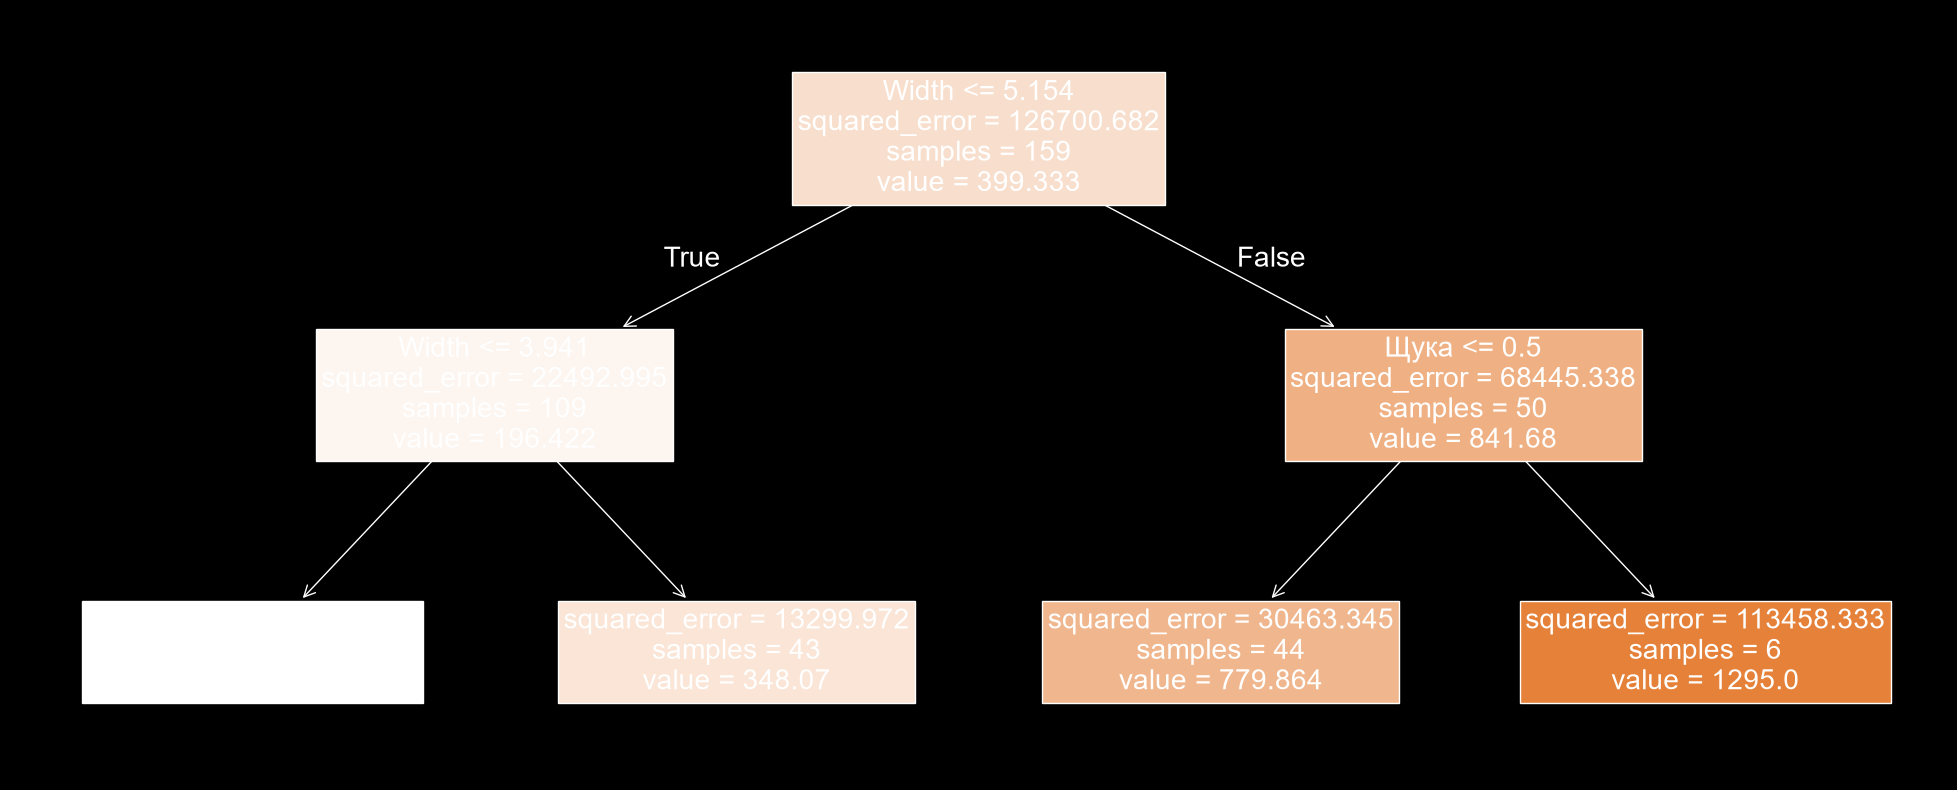

In [144]:
plt.figure(figsize = (25,10))
model5 = DecisionTreeRegressor(max_depth=2, min_samples_split=2).fit(X4, Y4)
tree.plot_tree(model5, feature_names=X4.columns, filled=True, fontsize=20)
plt.show()

5. Задача от заказчика